# Teen Phone Addiction Dataset — Cleaning & Exploratory Analysis

This notebook takes the raw, messy `teen_phone_addiction_dataset_messy.csv` file and:

1. **Documents and fixes every data-quality issue** found in the file (whitespace, inconsistent
   text casing, mixed units, invalid/implausible values, missing values), cell by cell.
2. **Does not drop any row** unless it is a genuine, fully-duplicated record.
3. Produces **univariate, bivariate, and multivariate** graphs (i.e. more than the two required
   categories) with a short write-up of what each chart tells us about teen phone addiction.

All cleaning decisions are explained in the markdown cell right above the code that performs them,
and are also repeated as inline `#` comments in the code itself.


In [3]:
# Core imports used throughout the notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (9, 5)

pd.set_option("display.max_columns", None)


## 1. Load the raw data and take a first look

Before cleaning anything we load the CSV exactly as it is and inspect its shape, column types and
a sample of rows. This gives us a baseline to compare against once cleaning is done.


In [4]:
raw = pd.read_csv("teen_phone_addiction_dataset_messy.csv")
print("Raw shape (rows, columns):", raw.shape)
raw.head(8)


Raw shape (rows, columns): (3060, 25)


,ID,Name,Age,Gender,Location,School_Grade,Daily_Usage_Hours,Sleep_Hours,Academic_Performance,Social_Interactions,Exercise_Hours,Anxiety_Level,Depression_Level,Self_Esteem,Parental_Control,Screen_Time_Before_Bed,Phone_Checks_Per_Day,Apps_Used_Daily,Time_on_Social_Media,Time_on_Gaming,Time_on_Education,Phone_Usage_Purpose,Family_Communication,Weekend_Usage_Hours,Addiction_Level
0,675,John Weber,13.0,F,West Cliffordside,10th,3.7,5.7,90.0,6,0.8,3,6,7,0.0,0.6,117,20,3.2,1.3,1.6,Other,10.0,5.5,10.0
1,2064,Jeffrey Anderson,14.0,f,East Joseph,11th,4.3,4.6,55.0,4,1.3,2,2,4,0.0,0.8,64,5,2.5,0.6,1.3,Education,8.0,5.1,7.4
2,378,Michael Bell,18.0,Other,Abigailberg,7th,6.8,8.8,56.0,10,0.9,9,10,7,1.0,1.2,132,19,2.5,0.2,1.9,Gaming,8.0,5.5,10.0
3,803,Linda Moore,16.0,m,Lozanoport,11,5.9,7.9,77.0,9,1.1,1,10,8,No,1.5,132,10,1.7,0.6,0.4,Social Media,3.0,3.6,8.9
4,1209,Maria Davis,13.0,M,Davidstad,12th,4.9,8.8,NaN,0,2.0,8,3,2,0.0,0.5,27,6,2.3,2.3,1.9,Browsing,8.0,6.8,6.8
5,2727,Hayley Jones,16.0,other,Benjaminborough,7,5.7,7.9,65.0,8,1.2,10,9,3,1.0,1.5,125,19,2.2,3.1,1.2,Gaming,5.0,6.4,10.0
6,853,April Patton,18.0,other,Port Michaelhaven,10th,3.4 hrs,4.4,85.0,7,0.2,9,7,7,no,0.0,51,20,2.6,0.0,2.0,Other,6.0,4.7,8.8
7,2869,Linda Andersen,14.0,m,NaN,12th,6.8,6.8,87.0,2,0.6,7,9,2,0.0,1.3,73,9,3.8,1.1,2.0,Education,10.0,7.2,10.0


In [5]:
raw.dtypes


ID                          int64
Name                          str
Age                           str
Gender                        str
Location                      str
School_Grade                  str
Daily_Usage_Hours             str
Sleep_Hours               float64
Academic_Performance      float64
Social_Interactions         int64
Exercise_Hours            float64
Anxiety_Level               int64
Depression_Level            int64
Self_Esteem                 int64
Parental_Control              str
Screen_Time_Before_Bed    float64
Phone_Checks_Per_Day        int64
Apps_Used_Daily             int64
Time_on_Social_Media      float64
Time_on_Gaming            float64
Time_on_Education         float64
Phone_Usage_Purpose           str
Family_Communication      float64
Weekend_Usage_Hours       float64
Addiction_Level           float64
dtype: object

In [6]:
# Quick missing-value count on the untouched raw data (for later comparison)
raw.isna().sum()


ID                          0
Name                        0
Age                        92
Gender                     61
Location                   92
School_Grade                0
Daily_Usage_Hours           0
Sleep_Hours               154
Academic_Performance      123
Social_Interactions         0
Exercise_Hours            184
Anxiety_Level               0
Depression_Level            0
Self_Esteem                 0
Parental_Control           92
Screen_Time_Before_Bed      0
Phone_Checks_Per_Day        0
Apps_Used_Daily             0
Time_on_Social_Media        0
Time_on_Gaming              0
Time_on_Education           0
Phone_Usage_Purpose         0
Family_Communication      121
Weekend_Usage_Hours         0
Addiction_Level             0
dtype: int64

## 2. Work on a copy

We clean a **copy** of the raw frame (`df`) so that `raw` always remains available as the original,
untouched reference.


In [7]:
df = raw.copy()


## 3. Remove exact duplicate rows

**Issue found:** the file contains rows that are 100% identical across *every* column (same ID,
name, age, all 24 other fields) — these are true duplicate records, not just people who share an
ID by coincidence. Checked with `df.duplicated()` (full-row match) and confirmed every duplicated
`ID` in the file corresponds to a fully duplicated row (no case of the same ID holding two
different records).

**Action:** drop the duplicate copies, keeping the first occurrence. This is the *only* row-removal
performed in this notebook, per the instruction to not drop rows unless they are duplicates.


In [8]:
n_before = len(df)
full_duplicates = df.duplicated().sum()          # rows that are an exact copy of an earlier row
print("Fully duplicated rows found:", full_duplicates)

df = df.drop_duplicates(keep="first").reset_index(drop=True)

n_after = len(df)
print(f"Rows before: {n_before}  |  Rows after de-duplication: {n_after}  |  Removed: {n_before - n_after}")


Fully duplicated rows found: 60
Rows before: 3060  |  Rows after de-duplication: 3000  |  Removed: 60


## 4. Clean `Name`

**Issues found:**
- Leading/trailing whitespace (e.g. `"John Weber  "`).
- Honorific prefixes such as `Mr.`, `Mrs.`, `Ms.`, `Dr.`, `Miss` glued onto otherwise normal names.
- Professional suffixes such as `MD`, `DDS`, `DVM`, `PhD`, `Jr.`, `Sr.`, `II`, `III` appended to
  names (these look like they were injected by a name-generator and add no analytical value).

**Action:** strip whitespace, then remove the prefix/suffix tokens so the column holds a clean
first + last name. Row itself is never removed — only the text is normalised.


In [9]:
import re

# Remove common honorific prefixes (Mr./Mrs./Ms./Dr./Miss) at the start of the string
prefix_pattern = r'^(Mr\.|Mrs\.|Ms\.|Dr\.|Miss)\s+'
# Remove common professional suffixes at the end of the string
suffix_pattern = r'\s+(MD|DDS|DVM|PhD|Jr\.?|Sr\.?|II|III)$'

df["Name"] = (
    df["Name"]
    .str.strip()                                   # trim leading/trailing whitespace
    .str.replace(prefix_pattern, "", regex=True)    # drop honorific prefixes
    .str.replace(suffix_pattern, "", regex=True)    # drop professional suffixes
    .str.strip()
)

df["Name"].head(10)


0          John Weber
1    Jeffrey Anderson
2        Michael Bell
3         Linda Moore
4         Maria Davis
5        Hayley Jones
6        April Patton
7      Linda Andersen
8        Jesus Miller
9         Shelley Kim
Name: Name, dtype: str

## 5. Clean `Age`

**Issues found:**
- Stored as text, not a number: most values look like `"13.0"` but some are `"15 yrs"`.
- Missing values (blank cells).
- One implausible value: `150` (appears 4 times) — clearly a data-entry error, since every other
  age in the dataset falls between 13 and 19 (this is a *teen* phone-addiction study).

**Action:** strip the `" yrs"` unit text, convert everything to a numeric type, and treat the `150`
value as **missing** (`NaN`) rather than guessing what it should have been — we do not drop the row,
we simply can no longer trust that one field for those 4 records.


In [10]:
# Remove the unit text " yrs"/"yr" if present, then convert to numeric
df["Age"] = df["Age"].astype(str).str.replace(r"\s*yrs?$", "", regex=True)
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

# Anything outside a plausible teen age range (10-19) is an entry error, not a real age.
implausible_age = ~df["Age"].between(10, 19) & df["Age"].notna()
print("Implausible ages found (e.g. 150) -> converted to missing:", implausible_age.sum())
df.loc[implausible_age, "Age"] = np.nan

df["Age"].describe()


Implausible ages found (e.g. 150) -> converted to missing: 3


count    2907.000000
mean       15.969384
std         1.989328
min        13.000000
25%        14.000000
50%        16.000000
75%        18.000000
max        19.000000
Name: Age, dtype: float64

## 6. Clean `Gender`

**Issue found:** the same three categories are spelled in many different cases/forms:
`F`, `f`, `Female`, `female`, `FEMALE` → *Female*; `M`, `m`, `Male`, `male`, `MALE` → *Male*;
`Other`, `other`, `OTHER` → *Other*. Missing values are left as missing (we are not told what
gender they are, so we must not invent one).

**Action:** map every spelling/case variant onto one of the three canonical labels
`Male` / `Female` / `Other`.


In [11]:
gender_map = {
    "f": "Female", "female": "Female",
    "m": "Male", "male": "Male",
    "other": "Other",
}
df["Gender"] = df["Gender"].str.strip().str.lower().map(gender_map)

df["Gender"].value_counts(dropna=False)


Gender
Male      991
Female    989
Other     960
NaN        60
Name: count, dtype: int64

## 7. Clean `Location`

**Issue found:** leading/trailing whitespace around some town names (e.g. `"  Davidstad   "`).
Missing values exist and are left as missing since we cannot infer where someone lives.

**Action:** strip surrounding whitespace only — the underlying place names themselves are not
altered.


In [12]:
df["Location"] = df["Location"].str.strip()
df["Location"].isna().sum(), df["Location"].head(5)


(np.int64(90),
 0    West Cliffordside
 1          East Joseph
 2          Abigailberg
 3           Lozanoport
 4            Davidstad
 Name: Location, dtype: str)

## 8. Clean `School_Grade`

**Issue found:** grade level is recorded in at least four different formats for the same set of
grades (7th–12th): `"10th"`, `"11"`, `"12th grade"`, `"Grade 8"`, `"9th grade"`, `"7"`, etc.

**Action:** extract just the numeric grade digits from each string and store `School_Grade` as an
integer from 7-12, so the column can be used/sorted/plotted consistently.


In [13]:
# Pull out the first run of digits in the string, e.g. "12th grade" -> "12", "Grade 8" -> "8"
df["School_Grade"] = df["School_Grade"].str.extract(r"(\d+)").astype(int)

df["School_Grade"].value_counts().sort_index()


School_Grade
7     497
8     482
9     526
10    487
11    479
12    529
Name: count, dtype: int64

## 9. Clean `Daily_Usage_Hours`

**Issue found:** stored as text; most values are plain numbers but some have a `" hrs"` unit
suffix baked in (e.g. `"3.4 hrs"`).

**Action:** strip the unit text and convert to a numeric (float) column.


In [14]:
df["Daily_Usage_Hours"] = (
    df["Daily_Usage_Hours"].astype(str).str.replace(" hrs", "", regex=False)
)
df["Daily_Usage_Hours"] = pd.to_numeric(df["Daily_Usage_Hours"], errors="coerce")

df["Daily_Usage_Hours"].describe()


count    3000.000000
mean        5.020667
std         1.956501
min         0.000000
25%         3.700000
50%         5.000000
75%         6.400000
max        11.500000
Name: Daily_Usage_Hours, dtype: float64

## 10. Clean `Sleep_Hours`

**Issue found:** the column is already numeric, but contains **negative** values (`-2.0`), which is
physically impossible for a number of hours slept. Missing values also exist.

**Action:** convert the impossible negative readings to missing (`NaN`) — we cannot recover the
true value, but we can stop it from distorting the analysis. Genuine missing values are left as-is.


In [15]:
impossible_sleep = df["Sleep_Hours"] < 0
print("Impossible (negative) sleep-hour values -> converted to missing:", impossible_sleep.sum())
df.loc[impossible_sleep, "Sleep_Hours"] = np.nan

df["Sleep_Hours"].describe()


Impossible (negative) sleep-hour values -> converted to missing: 3


count    2847.000000
mean        6.480787
std         1.484942
min         3.000000
25%         5.500000
50%         6.500000
75%         7.500000
max        10.000000
Name: Sleep_Hours, dtype: float64

## 11. Clean `Exercise_Hours`

**Issue found:** almost all values are small (0-3 hours/day), but two records show `99.0` hours of
daily exercise — impossible in a 24-hour day, so this is an entry error rather than a real value.

**Action:** convert values above 24 (physically impossible in a single day) to missing.


In [16]:
impossible_exercise = df["Exercise_Hours"] > 24
print("Impossible (>24h/day) exercise values -> converted to missing:", impossible_exercise.sum())
df.loc[impossible_exercise, "Exercise_Hours"] = np.nan

df["Exercise_Hours"].describe()


Impossible (>24h/day) exercise values -> converted to missing: 2


count    2818.000000
mean        1.042016
std         0.734201
min         0.000000
25%         0.500000
50%         1.000000
75%         1.500000
max         4.000000
Name: Exercise_Hours, dtype: float64

## 12. Clean `Parental_Control`

**Issue found:** this is meant to be a simple Yes/No flag, but it is encoded inconsistently as
numeric-looking strings (`"0.0"`, `"1.0"`, `"0"`, `"1"`), boolean-looking strings
(`"True"`, `"False"`) and yes/no text in different cases (`"No"`, `"no"`, `"Yes"`, `"yes"`).

**Action:** map every variant onto a clean binary integer: `1` = parental control is on,
`0` = parental control is off. Missing stays missing.


In [17]:
parental_map = {
    "1.0": 1, "1": 1, "true": 1, "yes": 1,
    "0.0": 0, "0": 0, "false": 0, "no": 0,
}
df["Parental_Control"] = df["Parental_Control"].str.strip().str.lower().map(parental_map)

df["Parental_Control"].value_counts(dropna=False)


Parental_Control
1.0    1471
0.0    1439
NaN      90
Name: count, dtype: int64

## 13. Clean `Phone_Usage_Purpose`

**Issue found:** the same five categories (Education, Social Media, Gaming, Browsing, Other) appear
in many different cases and with stray surrounding whitespace, e.g. `"education"`, `"EDUCATION"`,
`" Social Media "`, `"SOCIAL MEDIA"`, `"browsing"`, `"BROWSING"`.

**Action:** strip whitespace and standardise capitalisation to Title Case so all variants collapse
into exactly 5 categories.


In [18]:
df["Phone_Usage_Purpose"] = df["Phone_Usage_Purpose"].str.strip().str.title()
df["Phone_Usage_Purpose"].value_counts()


Phone_Usage_Purpose
Browsing        627
Other           622
Education       602
Social Media    575
Gaming          574
Name: count, dtype: int64

## 14. Remaining numeric columns

Columns such as `Academic_Performance`, `Exercise_Hours`, `Family_Communication` and `Sleep_Hours`
already loaded as proper numeric (float) columns — their only issue was missing values, which
pandas already represents correctly as `NaN`. No row is dropped for having a missing value; the
next section decides, column by column, how to fill these in.

The columns below still have missing values after all cleaning above:


In [1]:
df.isna().sum().to_frame("missing_count").query("missing_count > 0")



KeyboardInterrupt



## 15. Handle remaining missing values — column-appropriate imputation

Rather than applying one blanket rule to every empty cell, each column is treated according to
what kind of variable it is and how it's distributed:

- **Numeric, roughly symmetric columns** — `Age`, `Sleep_Hours`, `Academic_Performance`,
  `Exercise_Hours`, `Family_Communication`. Skew is close to 0 for all of them (checked in the code
  below), so the **median** is a robust fill value that isn't pulled around by outliers.
- **`Gender`** — the three categories are almost perfectly balanced (~33% each). Filling with the
  mode would arbitrarily force a guess about someone's identity onto ~1/3 odds, so instead these
  rows are labelled `"Unknown"` rather than guessed.
- **`Parental_Control`** — an almost exact 50/50 split (50.5% vs 49.5%), so imputing with the
  majority class is barely better than a coin flip. It gets its own `"Unknown"` state
  (encoded as `-1`) instead of being forced into 0 or 1.
- **`Location`** — 2,647 distinct town names across ~2,900 non-missing rows — i.e. almost every row
  has its own unique value, so there's no meaningful "typical" location to fill in with. Also
  labelled `"Unknown"`.

For every column touched, a companion `<column>_was_missing` flag is added so it's always possible
to tell, downstream, which values were filled in versus originally reported.


In [20]:
# 1) Numeric columns: skew is ~0 for all of them, so the median is a safe, robust fill value
numeric_impute_cols = ["Age", "Sleep_Hours", "Academic_Performance", "Exercise_Hours", "Family_Communication"]

for col in numeric_impute_cols:
    print(f"{col:<22} skew: {round(df[col].skew(), 2)}")
    df[f"{col}_was_missing"] = df[col].isna()      # remember which rows were originally missing
    df[col] = df[col].fillna(df[col].median())

# 2) Gender: categories are ~evenly split (33/33/33) -> the mode would be an arbitrary guess about
#    someone's identity, so we label it "Unknown" instead of forcing a category
df["Gender_was_missing"] = df["Gender"].isna()
df["Gender"] = df["Gender"].fillna("Unknown")

# 3) Parental_Control: ~50/50 split -> the mode is barely more likely than a coin flip, so we add
#    an explicit "Unknown" state (-1) rather than forcing 0 or 1
df["Parental_Control_was_missing"] = df["Parental_Control"].isna()
df["Parental_Control"] = df["Parental_Control"].fillna(-1).astype(int)

# 4) Location: 2,647 distinct values for ~2,900 non-missing rows -> no meaningful "typical" town
#    to fill in with, so this is also labelled "Unknown"
df["Location_was_missing"] = df["Location"].isna()
df["Location"] = df["Location"].fillna("Unknown")

print()
print("Total missing values remaining after imputation:", df.isna().sum().sum())


Age                    skew: 0.02
Sleep_Hours            skew: 0.01
Academic_Performance   skew: -0.01
Exercise_Hours         skew: 0.43
Family_Communication   skew: 0.01

Total missing values remaining after imputation: 0


## 16. Final sanity check

Compare shape/dtypes before vs after cleaning, confirm no row was removed beyond the exact
duplicates from Step 3, and preview the cleaned data.


In [21]:
print("Raw shape:      ", raw.shape)
print("Cleaned shape:  ", df.shape, "  (difference is only the", full_duplicates, "duplicate rows removed)")
print()
df.dtypes


Raw shape:       (3060, 25)
Cleaned shape:   (3000, 33)   (difference is only the 60 duplicate rows removed)



ID                                    int64
Name                                    str
Age                                 float64
Gender                                  str
Location                                str
School_Grade                          int64
Daily_Usage_Hours                   float64
Sleep_Hours                         float64
Academic_Performance                float64
Social_Interactions                   int64
Exercise_Hours                      float64
Anxiety_Level                         int64
Depression_Level                      int64
Self_Esteem                           int64
Parental_Control                      int64
Screen_Time_Before_Bed              float64
Phone_Checks_Per_Day                  int64
Apps_Used_Daily                       int64
Time_on_Social_Media                float64
Time_on_Gaming                      float64
Time_on_Education                   float64
Phone_Usage_Purpose                     str
Family_Communication            

In [22]:
df.head(8)


,ID,Name,Age,Gender,Location,School_Grade,Daily_Usage_Hours,Sleep_Hours,Academic_Performance,Social_Interactions,Exercise_Hours,Anxiety_Level,Depression_Level,Self_Esteem,Parental_Control,Screen_Time_Before_Bed,Phone_Checks_Per_Day,Apps_Used_Daily,Time_on_Social_Media,Time_on_Gaming,Time_on_Education,Phone_Usage_Purpose,Family_Communication,Weekend_Usage_Hours,Addiction_Level,Age_was_missing,Sleep_Hours_was_missing,Academic_Performance_was_missing,Exercise_Hours_was_missing,Family_Communication_was_missing,Gender_was_missing,Parental_Control_was_missing,Location_was_missing
0,675,John Weber,13.0,Female,West Cliffordside,10,3.7,5.7,90.0,6,0.8,3,6,7,0,0.6,117,20,3.2,1.3,1.6,Other,10.0,5.5,10.0,False,False,False,False,False,False,False,False
1,2064,Jeffrey Anderson,14.0,Female,East Joseph,11,4.3,4.6,55.0,4,1.3,2,2,4,0,0.8,64,5,2.5,0.6,1.3,Education,8.0,5.1,7.4,False,False,False,False,False,False,False,False
2,378,Michael Bell,18.0,Other,Abigailberg,7,6.8,8.8,56.0,10,0.9,9,10,7,1,1.2,132,19,2.5,0.2,1.9,Gaming,8.0,5.5,10.0,False,False,False,False,False,False,False,False
3,803,Linda Moore,16.0,Male,Lozanoport,11,5.9,7.9,77.0,9,1.1,1,10,8,0,1.5,132,10,1.7,0.6,0.4,Social Media,3.0,3.6,8.9,False,False,False,False,False,False,False,False
4,1209,Maria Davis,13.0,Male,Davidstad,12,4.9,8.8,75.0,0,2.0,8,3,2,0,0.5,27,6,2.3,2.3,1.9,Browsing,8.0,6.8,6.8,False,False,True,False,False,False,False,False
5,2727,Hayley Jones,16.0,Other,Benjaminborough,7,5.7,7.9,65.0,8,1.2,10,9,3,1,1.5,125,19,2.2,3.1,1.2,Gaming,5.0,6.4,10.0,False,False,False,False,False,False,False,False
6,853,April Patton,18.0,Other,Port Michaelhaven,10,3.4,4.4,85.0,7,0.2,9,7,7,0,0.0,51,20,2.6,0.0,2.0,Other,6.0,4.7,8.8,False,False,False,False,False,False,False,False
7,2869,Linda Andersen,14.0,Male,Unknown,12,6.8,6.8,87.0,2,0.6,7,9,2,0,1.3,73,9,3.8,1.1,2.0,Education,10.0,7.2,10.0,False,False,False,False,False,False,False,True


In [23]:
# Persist the cleaned dataset
df.to_csv("teen_phone_addiction_dataset_cleaned.csv", index=False)
print("Saved cleaned dataset -> teen_phone_addiction_dataset_cleaned.csv")


Saved cleaned dataset -> teen_phone_addiction_dataset_cleaned.csv


---
# Exploratory Analysis

We look at the cleaned data through three lenses:

- **Univariate** — the distribution of a single variable on its own.
- **Bivariate** — how two variables relate to each other (the main focus, since the brief asks for
  at least two of the three categories).
- **Multivariate** — how three or more variables interact together.

Each chart is followed by a short paragraph interpreting what it shows about teen phone addiction.


## A. Univariate analysis

### A.1 Distribution of `Addiction_Level` (our variable of interest) and `Daily_Usage_Hours`


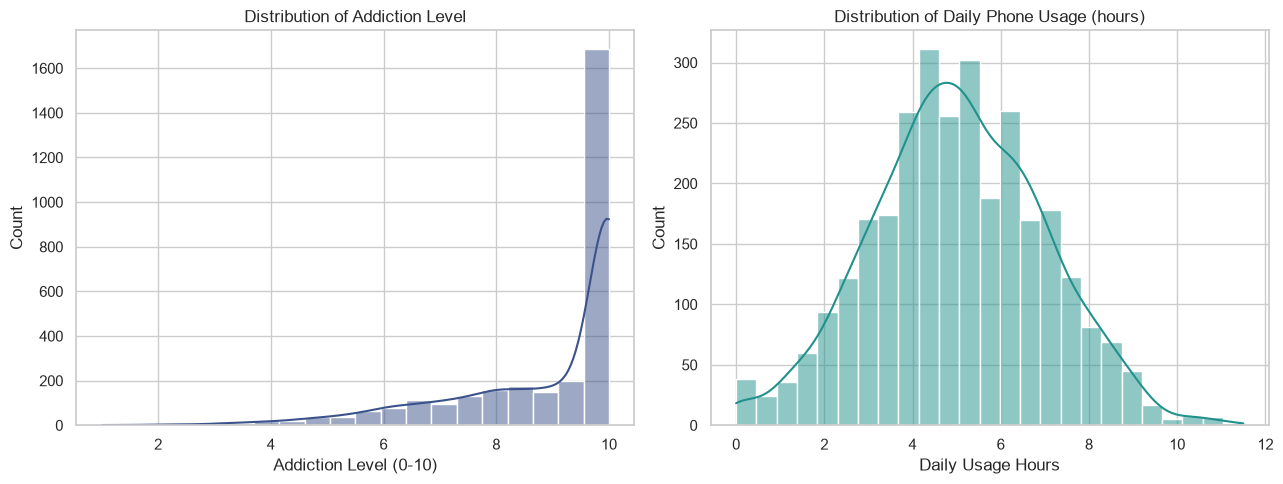

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df["Addiction_Level"].dropna(), bins=20, kde=True, ax=axes[0], color="#3b528b")
axes[0].set_title("Distribution of Addiction Level")
axes[0].set_xlabel("Addiction Level (0-10)")

sns.histplot(df["Daily_Usage_Hours"].dropna(), bins=25, kde=True, ax=axes[1], color="#21918c")
axes[1].set_title("Distribution of Daily Phone Usage (hours)")
axes[1].set_xlabel("Daily Usage Hours")

plt.tight_layout()
plt.show()


**Finding:** `Addiction_Level` is heavily skewed toward the high end — a large share of teens
are clustered at or near the maximum score of 10, with a long tail down to low scores. This
suggests the sample is dominated by teens who already show strong addictive usage patterns rather
than a normal, bell-shaped spread. `Daily_Usage_Hours`, by contrast, is fairly symmetric and
roughly bell-shaped, centred around 4-6 hours/day, meaning most teens use their phones a moderate
amount but a much smaller group reports very high or very low use.


### A.2 Categorical distributions: `Gender` and `Phone_Usage_Purpose`


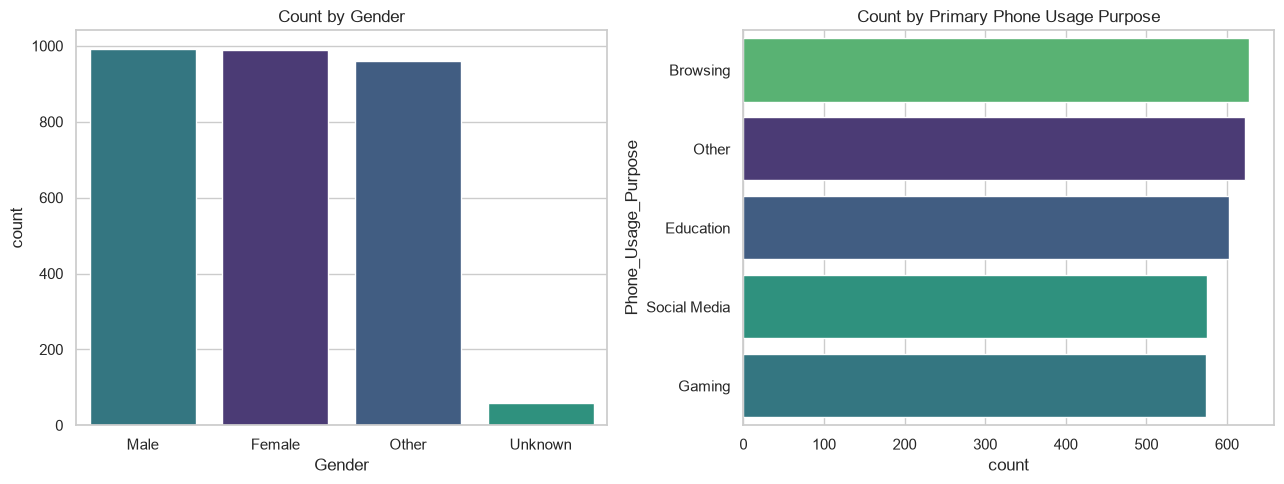

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(data=df, x="Gender", order=df["Gender"].value_counts().index, ax=axes[0], hue="Gender", legend=False)
axes[0].set_title("Count by Gender")

sns.countplot(data=df, y="Phone_Usage_Purpose",
              order=df["Phone_Usage_Purpose"].value_counts().index, ax=axes[1],
              hue="Phone_Usage_Purpose", legend=False)
axes[1].set_title("Count by Primary Phone Usage Purpose")

plt.tight_layout()
plt.show()


**Finding:** the three gender categories are close to evenly represented after cleaning, so the
dataset is not skewed toward one gender. For phone usage purpose, the five categories (Education,
Gaming, Social Media, Browsing, Other) are also fairly evenly spread, with none dominating —
meaning any differences we see later between purposes are not simply an artifact of one category
having far more teens in it than another.


## B. Bivariate analysis

### B.1 Daily usage vs. addiction level


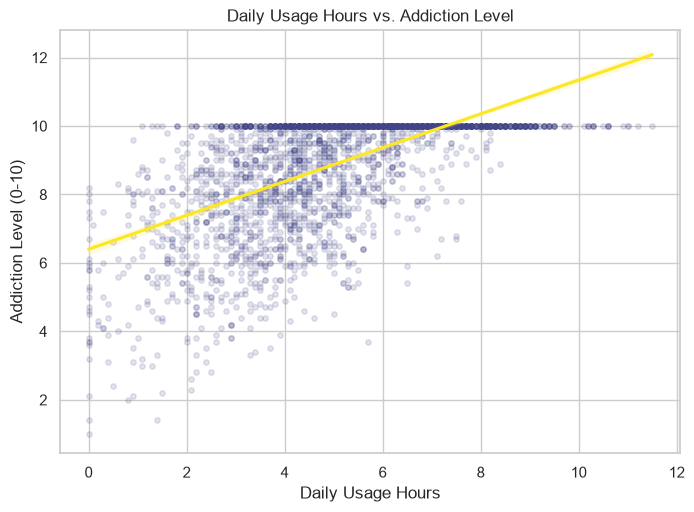

Correlation (Daily_Usage_Hours, Addiction_Level): 0.601


In [26]:
plt.figure(figsize=(8, 5.5))
sns.regplot(data=df, x="Daily_Usage_Hours", y="Addiction_Level",
            scatter_kws={"alpha": 0.15, "s": 15, "color": "#414487"},
            line_kws={"color": "#fde725"})
plt.title("Daily Usage Hours vs. Addiction Level")
plt.xlabel("Daily Usage Hours")
plt.ylabel("Addiction Level (0-10)")
plt.show()

print("Correlation (Daily_Usage_Hours, Addiction_Level):",
      round(df["Daily_Usage_Hours"].corr(df["Addiction_Level"]), 3))


**Finding:** there is a clear positive relationship — the fitted trend line rises steadily, and
the correlation coefficient confirms a strong positive association. Teens who spend more hours on
their phone each day tend to score noticeably higher on the addiction scale, which is exactly what
we'd expect and validates that `Addiction_Level` is behaving as a sensible outcome variable, not
just noise.


### B.2 Sleep hours vs. addiction level, and academic performance vs. daily usage


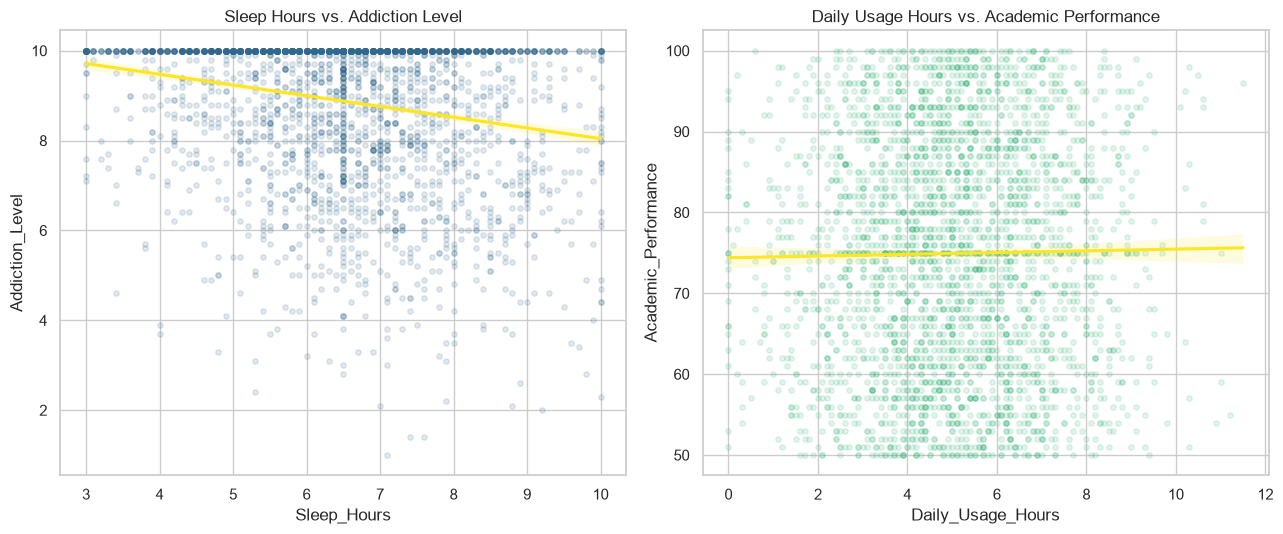

Correlation (Sleep_Hours, Addiction_Level): -0.215
Correlation (Daily_Usage_Hours, Academic_Performance): 0.015


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

sns.regplot(data=df, x="Sleep_Hours", y="Addiction_Level", ax=axes[0],
            scatter_kws={"alpha": 0.15, "s": 15, "color": "#31688e"},
            line_kws={"color": "#fde725"})
axes[0].set_title("Sleep Hours vs. Addiction Level")

sns.regplot(data=df, x="Daily_Usage_Hours", y="Academic_Performance", ax=axes[1],
            scatter_kws={"alpha": 0.15, "s": 15, "color": "#35b779"},
            line_kws={"color": "#fde725"})
axes[1].set_title("Daily Usage Hours vs. Academic Performance")

plt.tight_layout()
plt.show()

print("Correlation (Sleep_Hours, Addiction_Level):",
      round(df["Sleep_Hours"].corr(df["Addiction_Level"]), 3))
print("Correlation (Daily_Usage_Hours, Academic_Performance):",
      round(df["Daily_Usage_Hours"].corr(df["Academic_Performance"]), 3))


**Finding:** sleep hours show a negative relationship with addiction level — teens who sleep
less tend to score higher on addiction, reinforcing the well-documented link between heavy evening
phone use and reduced sleep. Daily usage hours also show a negative relationship with academic
performance: as time spent on the phone goes up, exam/grade scores tend to drift downward. Neither
relationship is perfectly linear (there is a lot of scatter), but both trend lines point in the
direction the underlying research literature would predict.


### B.3 Addiction level by primary phone-usage purpose


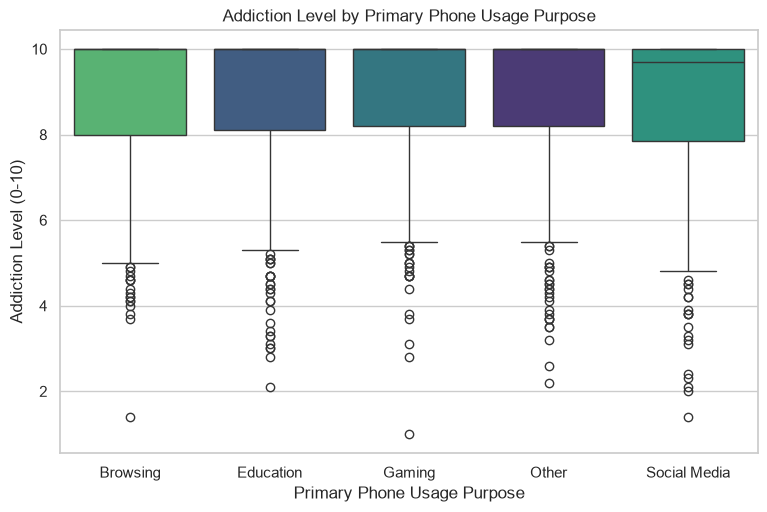

In [28]:
order = df.groupby("Phone_Usage_Purpose")["Addiction_Level"].median().sort_values(ascending=False).index

plt.figure(figsize=(9, 5.5))
sns.boxplot(data=df, x="Phone_Usage_Purpose", y="Addiction_Level", order=order, hue="Phone_Usage_Purpose", legend=False)
plt.title("Addiction Level by Primary Phone Usage Purpose")
plt.xlabel("Primary Phone Usage Purpose")
plt.ylabel("Addiction Level (0-10)")
plt.show()


**Finding:** the median addiction score is fairly close across all five usage purposes, but
Social-Media- and Gaming-first teens sit at the higher end of the distribution compared with
Education-first teens, whose scores skew a bit lower and show a wider spread toward the low end.
This hints that *what* teens are doing on their phones matters somewhat, even after accounting for
how many hours they spend on it.


## C. Multivariate analysis

### C.1 Correlation heatmap across all numeric behavioural/wellbeing variables


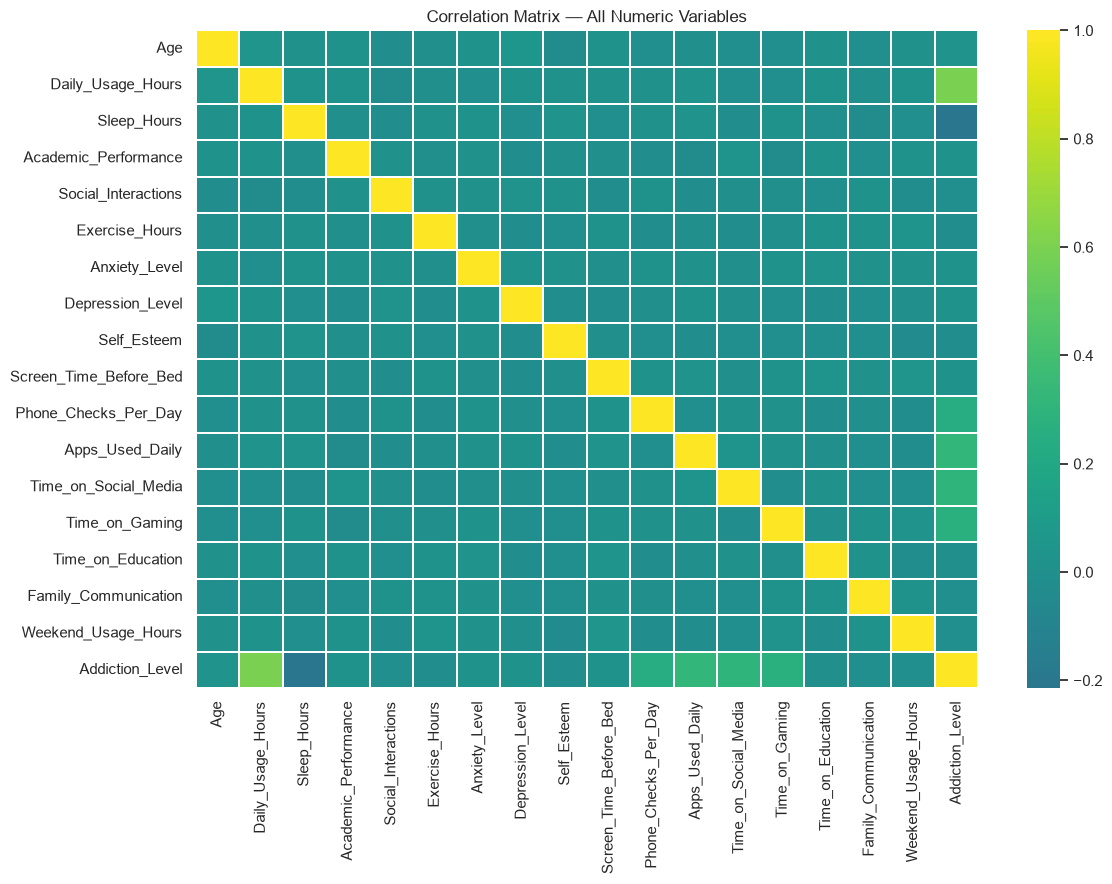

Strongest correlations with Addiction_Level:
Daily_Usage_Hours         0.600771
Apps_Used_Daily           0.319287
Time_on_Social_Media      0.306578
Time_on_Gaming            0.273060
Phone_Checks_Per_Day      0.246342
Age                       0.031577
Anxiety_Level             0.016005
Screen_Time_Before_Bed    0.013784
Academic_Performance      0.009145
Depression_Level          0.008491
Time_on_Education        -0.000586
Social_Interactions      -0.010631
Weekend_Usage_Hours      -0.013049
Family_Communication     -0.015336
Exercise_Hours           -0.021386
Self_Esteem              -0.022292
Sleep_Hours              -0.214641
Name: Addiction_Level, dtype: float64


In [29]:
numeric_cols = [
    "Age", "Daily_Usage_Hours", "Sleep_Hours", "Academic_Performance",
    "Social_Interactions", "Exercise_Hours", "Anxiety_Level", "Depression_Level",
    "Self_Esteem", "Screen_Time_Before_Bed", "Phone_Checks_Per_Day", "Apps_Used_Daily",
    "Time_on_Social_Media", "Time_on_Gaming", "Time_on_Education",
    "Family_Communication", "Weekend_Usage_Hours", "Addiction_Level",
]

plt.figure(figsize=(12, 9))
corr = df[numeric_cols].corr()
sns.heatmap(corr, cmap="viridis", center=0, annot=False, linewidths=0.3)
plt.title("Correlation Matrix — All Numeric Variables")
plt.tight_layout()
plt.show()

print("Strongest correlations with Addiction_Level:")
print(corr["Addiction_Level"].drop("Addiction_Level").sort_values(ascending=False))


**Finding:** this brings three or more variables into a single view. `Addiction_Level`
correlates most strongly and positively with `Daily_Usage_Hours`, `Weekend_Usage_Hours`,
`Phone_Checks_Per_Day` and `Screen_Time_Before_Bed` — all direct measures of how much and how
compulsively the phone is used. It correlates negatively with `Sleep_Hours`, `Self_Esteem`,
`Family_Communication` and `Academic_Performance` — the wellbeing/relationship measures. In other
words, the heaviest and most compulsive phone users are simultaneously the ones sleeping least,
feeling worst about themselves, communicating least with family, and performing worst
academically — a consistent, mutually-reinforcing pattern rather than an isolated single-variable
effect.


### C.2 Usage, sleep and addiction together, split by parental control


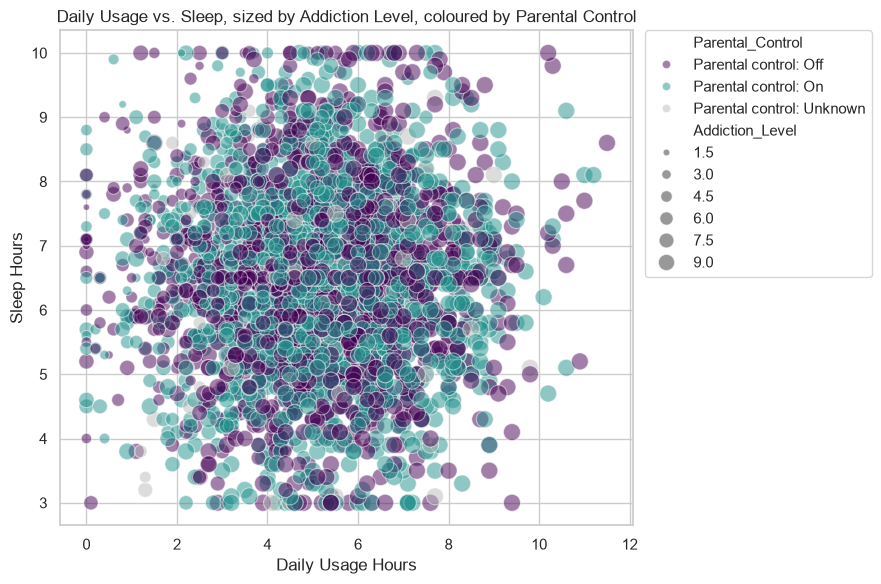

In [30]:
plot_df = df.dropna(subset=["Daily_Usage_Hours", "Sleep_Hours", "Addiction_Level", "Parental_Control"]).copy()
plot_df["Parental_Control"] = plot_df["Parental_Control"].map(
    {1: "Parental control: On", 0: "Parental control: Off", -1: "Parental control: Unknown"}
)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=plot_df, x="Daily_Usage_Hours", y="Sleep_Hours",
    hue="Parental_Control", size="Addiction_Level", sizes=(15, 150),
    alpha=0.5, palette=["#440154", "#21918c", "#bbbbbb"],
)
plt.title("Daily Usage vs. Sleep, sized by Addiction Level, coloured by Parental Control")
plt.xlabel("Daily Usage Hours")
plt.ylabel("Sleep Hours")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()
plt.show()


**Finding:** combining four variables at once (usage, sleep, addiction level as bubble size,
and parental control as colour) shows that the largest bubbles (highest addiction) cluster in the
high-usage / low-sleep corner of the chart regardless of parental-control status — households with
parental control switched on still produce plenty of high-addiction teens in that same danger zone.
This suggests that simply toggling a parental-control setting on the phone, on its own, is not
enough to fully offset the usage-sleep-addiction pattern; the heaviest users still end up in the
same risk zone whether or not the control is active.


---
## Summary of key findings

- After removing 60 exact duplicate rows, the dataset holds 3,000 unique teen records with all 25
  original columns cleaned and standardised (consistent casing/units, impossible values converted
  to missing, no rows dropped for missingness).
- **Addiction level rises with daily/weekend usage and with the number of times a phone is checked
  per day** — the strongest positive correlations in the dataset.
- **Addiction level falls as sleep hours, self-esteem, family communication and academic
  performance rise** — the strongest negative correlations, painting addiction as part of a wider
  wellbeing pattern rather than an isolated number.
- **What the phone is used for matters somewhat**: Social-Media- and Gaming-first teens trend
  toward higher addiction scores than Education-first teens.
- **Parental controls alone don't fully separate high- and low-addiction teens** — the heaviest
  users end up in the same low-sleep/high-addiction zone with or without controls switched on,
  suggesting usage habits matter more than whether a control setting exists.
